In [1]:
# conda env 'vis2_clone'
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import seaborn as sns

PROJECT_ROOT = Path().resolve().parent.parent.parent
sys.path.append(str(PROJECT_ROOT))
plt.style.use('seaborn-v0_8-paper')

In [2]:
from src.Retrieval import Retrieval
from src.utils.util import set_labels

In [3]:
def set_dist(df, bins, xmax=17.6, ymax=17.6):
    df['xp'] = xmax - df['x']
    df['yp'] = ymax - df['y']
    df['dist to boundary'] = df.loc[:,['x', 'xp', 'y', 'yp']].min(axis=1).round(3)
    df['dist bin'] = pd.cut(df['dist to boundary'], bins=bins)
    return df.drop(columns=['xp', 'yp'])

In [4]:
EXPERIMENT_SET = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08'
RETRIEVAL = EXPERIMENT_SET / 'default'
FIGURE_OUT = RETRIEVAL / 'figures'
FIGURE_OUT.mkdir(parents=True, exist_ok=True)
savefigs = True

In [5]:
ro = Retrieval(RETRIEVAL)
ro.load_retrieval(extinction_th=[0.3, np.inf], tau_th=[0.3, np.inf])
rp = Retrieval(EXPERIMENT_SET / 'HBC' / 'periodic')
rp.load_retrieval(extinction_th=[0.3, np.inf], tau_th=[0.3, np.inf])

In [6]:
bins = np.arange(0, 9.2, 0.275) - 0.275/2
open = ro.to_dataframe(0.67, 'cloud', 'extinction')
open = set_dist(open, bins, xmax=17.6, ymax=17.6)
open['Horizontal Boundary Condition'] = 'open'
per = rp.to_dataframe(0.67, 'cloud', 'extinction')
per = set_dist(per, bins, xmax=17.6, ymax=17.6)
per['Horizontal Boundary Condition'] = 'periodic'
df = pd.concat((open, per))

<Axes: xlabel='dist bin', ylabel='extinction'>

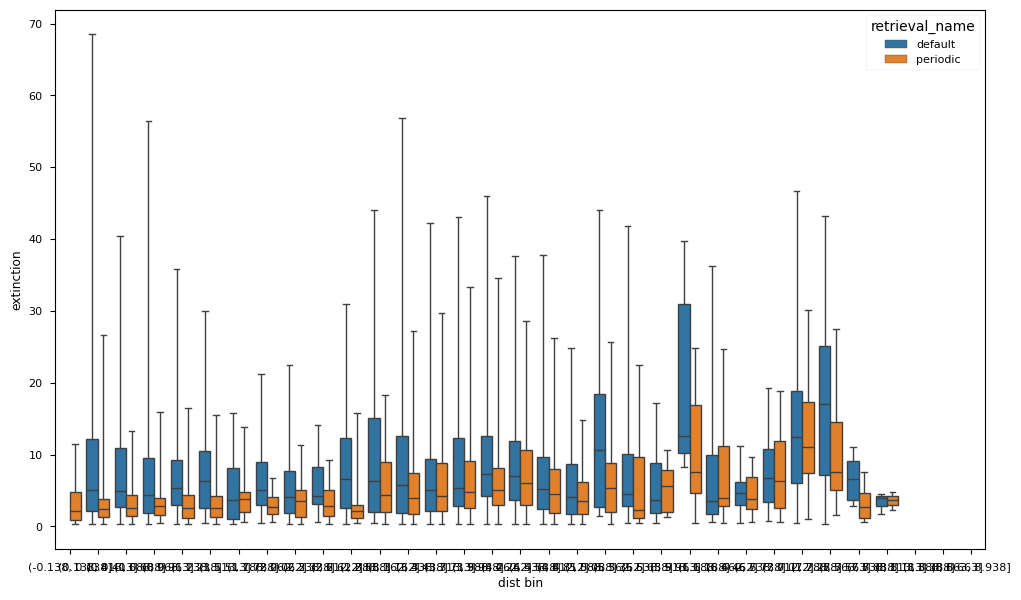

In [7]:
f, ax = plt.subplots(1, 1, figsize=(12, 7))
sns.boxplot(df, x='dist bin', y='extinction', hue='retrieval_name', whis=(0, 100), ax=ax)

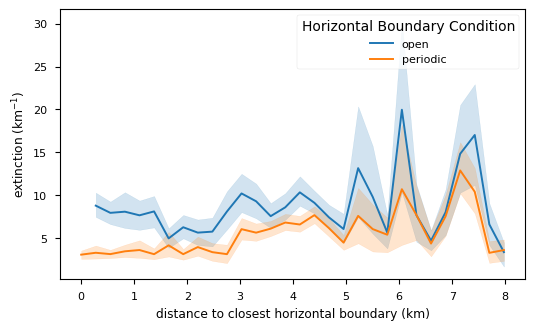

In [8]:
f, ax = plt.subplots(1, 1, figsize=(6, 3.5))
sns.lineplot(df, x='dist to boundary', y='extinction', hue='Horizontal Boundary Condition', errorbar=('ci',95), ax=ax)
ax.set_xlabel('distance to closest horizontal boundary (km)')
ax.set_ylabel(r'extinction (km$^{-1}$)')

if(savefigs):
    plt.savefig(
        FIGURE_OUT / 'hbc.png',
        format='png',
        dpi=300,
        bbox_inches='tight',
        transparent=False
    )